# House Prices: from baseline to blend, one measured step at a time

**Task.** Predict the sale price of 1,459 houses in Ames, Iowa, from 79 descriptive columns
(size, age, quality, location, ...). We learn from 1,460 houses whose prices we know.

**Metric.** Kaggle scores the RMSE between the *log* of our predicted price and the *log* of the
true price. Working in logs means a 10% miss counts the same on a cheap house as on an
expensive one.

**How this notebook is organised.** Part 1 explores the data. Part 2 builds a baseline and the
cross-validation tools. Part 3 adds feature engineering one step at a time. Part 4 compares
models. Part 5 blends them. Every step's score goes into one results table, so the whole
pathway can be read off at the end.

*Numbers quoted in the text come from the reference run. A run on Kaggle may differ slightly
(around the 4th decimal) because library versions differ.*

## Part 1: Exploratory data analysis (EDA)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# On Kaggle the data sits under /kaggle/input; locally it sits next to this repo's v2 folder.
CANDIDATES = [Path("/kaggle/input/house-prices-advanced-regression-techniques"),
              *sorted(path.parent for path in Path("/kaggle/input").glob("**/train.csv")),
              Path("../house-prices-advanced-regression-techniques"),
              Path("house-prices-advanced-regression-techniques")]
DATA_DIR = next((path for path in CANDIDATES if (path / "train.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Could not find train.csv. Looked in: " + ", ".join(map(str, CANDIDATES))
                            + ". On Kaggle, attach the competition data with 'Add Input'.")

ON_KAGGLE = Path("/kaggle/working").exists()
OUT_DIR = Path("/kaggle/working") if ON_KAGGLE else DATA_DIR.parent / "v2" / "results"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)


def read_csv(name):
    # The string "None" is a real category (e.g. MasVnrType = no masonry veneer).
    # Only "NA" and empty cells mean missing.
    return pd.read_csv(DATA_DIR / name, keep_default_na=False, na_values=["NA", ""])


train = read_csv("train.csv")
test = read_csv("test.csv")
sample = read_csv("sample_submission.csv")
print("train:", train.shape, " test:", test.shape)

train: (1460, 81)  test: (1459, 80)


### 1.1 First look
`train` has 81 columns: `Id`, 79 descriptive columns, and the target `SalePrice`.
`test` has the same columns except `SalePrice`, which is what we must predict.

In [2]:
print(train.dtypes.value_counts())
train.head()

object     43
int64      35
float64     3
Name: count, dtype: int64


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 1.2 The target: SalePrice
The middle half of houses sell for $130k–$214k, but a long tail runs up to $755k. A *right-skewed*
target like this pulls a linear model towards the few expensive houses. Taking the log
makes the distribution almost symmetric, and it is also the scale Kaggle scores on.

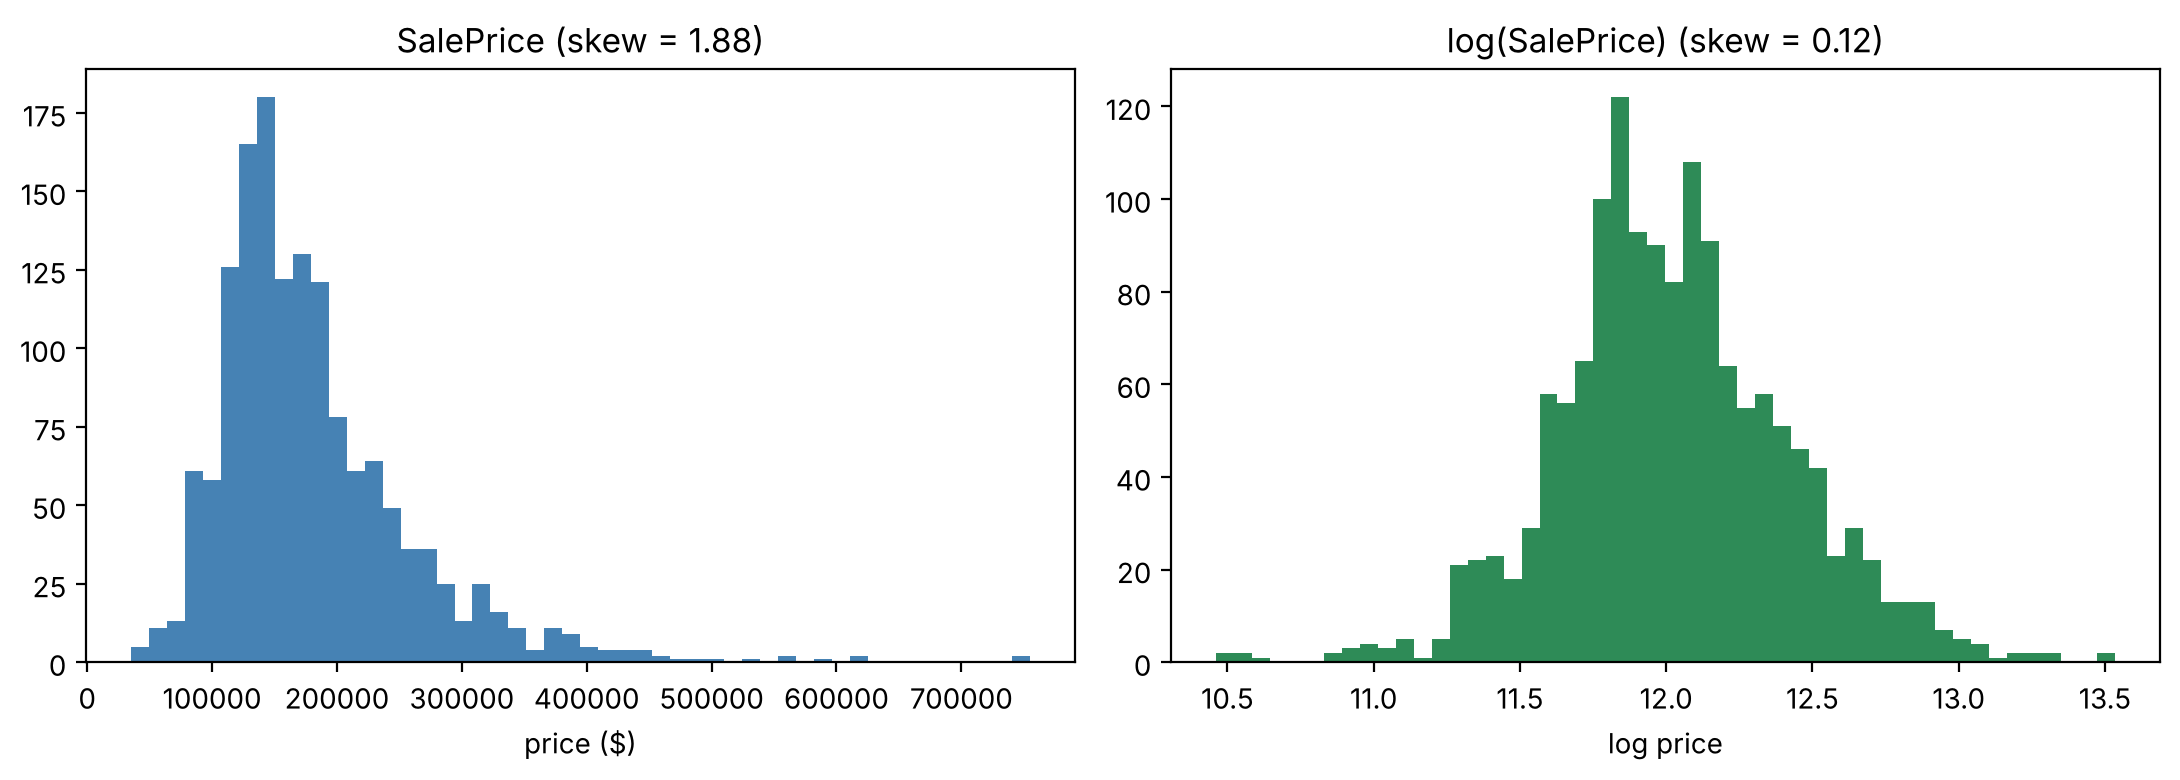

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(train.SalePrice, bins=50, color="steelblue")
axes[0].set(title=f"SalePrice (skew = {train.SalePrice.skew():.2f})", xlabel="price ($)")
axes[1].hist(np.log(train.SalePrice), bins=50, color="seagreen")
axes[1].set(title=f"log(SalePrice) (skew = {np.log(train.SalePrice).skew():.2f})", xlabel="log price")
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "01_saleprice_distribution.png", dpi=120)
plt.show()

### 1.3 Missing values: two very different kinds
`data_description.txt` says that for many columns **NA means "this house doesn't have one"**:
no pool, no garage, no basement, no fence. That is information, not a gap.
For other columns (e.g. `LotFrontage`), NA really means *we don't know*.
Part 3 treats the two kinds differently.

A few columns are missing **only in test** (e.g. `MSZoning`, `GarageCars`). Our pipeline
must cope with gaps it never saw during training.

Columns missing only in test: ['MSZoning', 'BsmtFinSF2', 'BsmtUnfSF', 'Utilities', 'Exterior2nd', 'Exterior1st', 'BsmtFinSF1', 'TotalBsmtSF', 'BsmtHalfBath', 'KitchenQual', 'Functional', 'BsmtFullBath', 'GarageArea', 'GarageCars', 'SaleType']


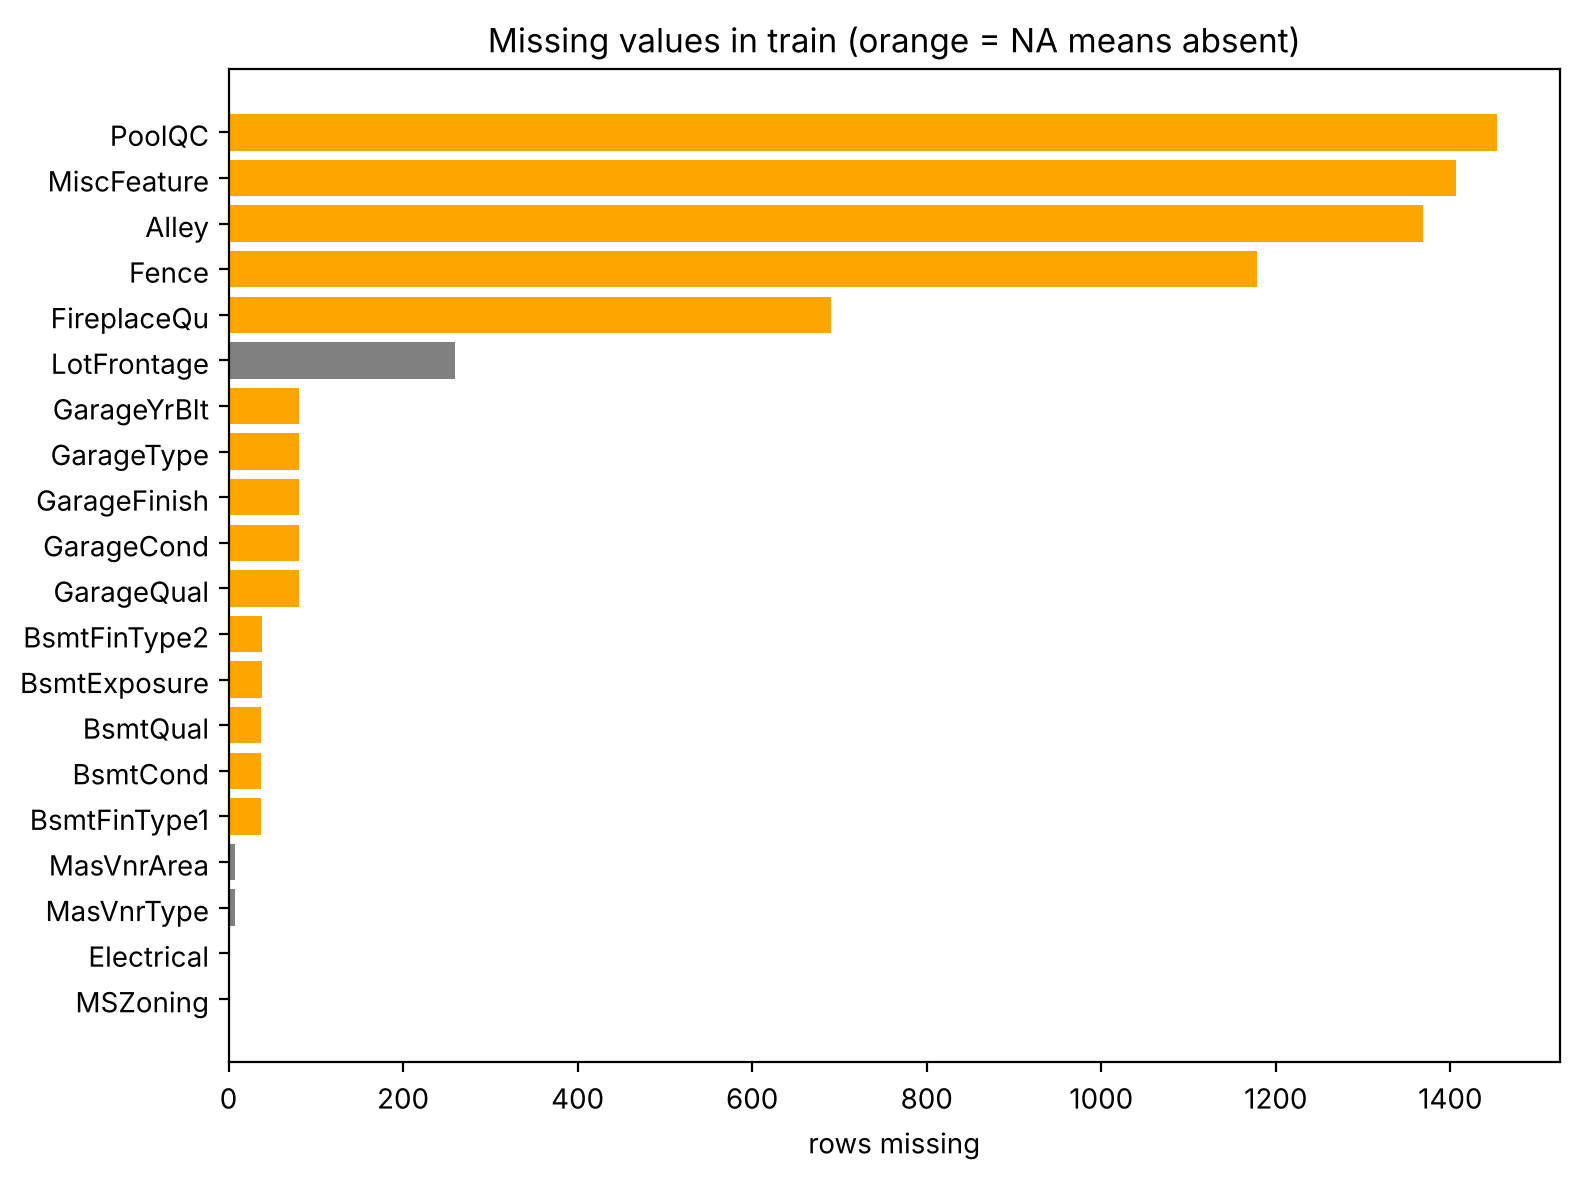

,train,test,kind
PoolQC,1453,1456,NA = absent
MiscFeature,1406,1408,NA = absent
Alley,1369,1352,NA = absent
Fence,1179,1169,NA = absent
FireplaceQu,690,730,NA = absent
LotFrontage,259,227,truly unknown
GarageYrBlt,81,78,NA = absent
GarageType,81,76,NA = absent
GarageFinish,81,78,NA = absent
GarageCond,81,78,NA = absent


In [4]:
ABSENT_MEANING = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
                  "GarageType", "GarageFinish", "GarageQual", "GarageCond", "GarageYrBlt",
                  "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]

missing = pd.DataFrame({"train": train.drop(columns="SalePrice").isna().sum(),
                        "test": test.isna().sum()})
missing = missing[(missing.train + missing.test) > 0]
missing["kind"] = np.where(missing.index.isin(ABSENT_MEANING), "NA = absent", "truly unknown")
missing = missing.sort_values("train", ascending=False)
print("Columns missing only in test:", missing.index[missing.train.eq(0)].tolist())

top = missing.head(20).iloc[::-1]
colors = np.where(top.kind.eq("NA = absent"), "orange", "gray")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.train, color=colors)
ax.set(title="Missing values in train (orange = NA means absent)", xlabel="rows missing")
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "02_missing_values.png", dpi=120)
plt.show()
missing

### 1.4 Outliers
Living area (`GrLivArea`) is one of the strongest predictors. But two houses are huge
(over 4,000 sq ft) yet sold cheaply (under $300k). Both were *Partial* sales of new builds,
so they don't follow the normal price pattern. A model that tries to fit them bends its
line for every other house. Part 3 (Step 6) tests removing them from training.

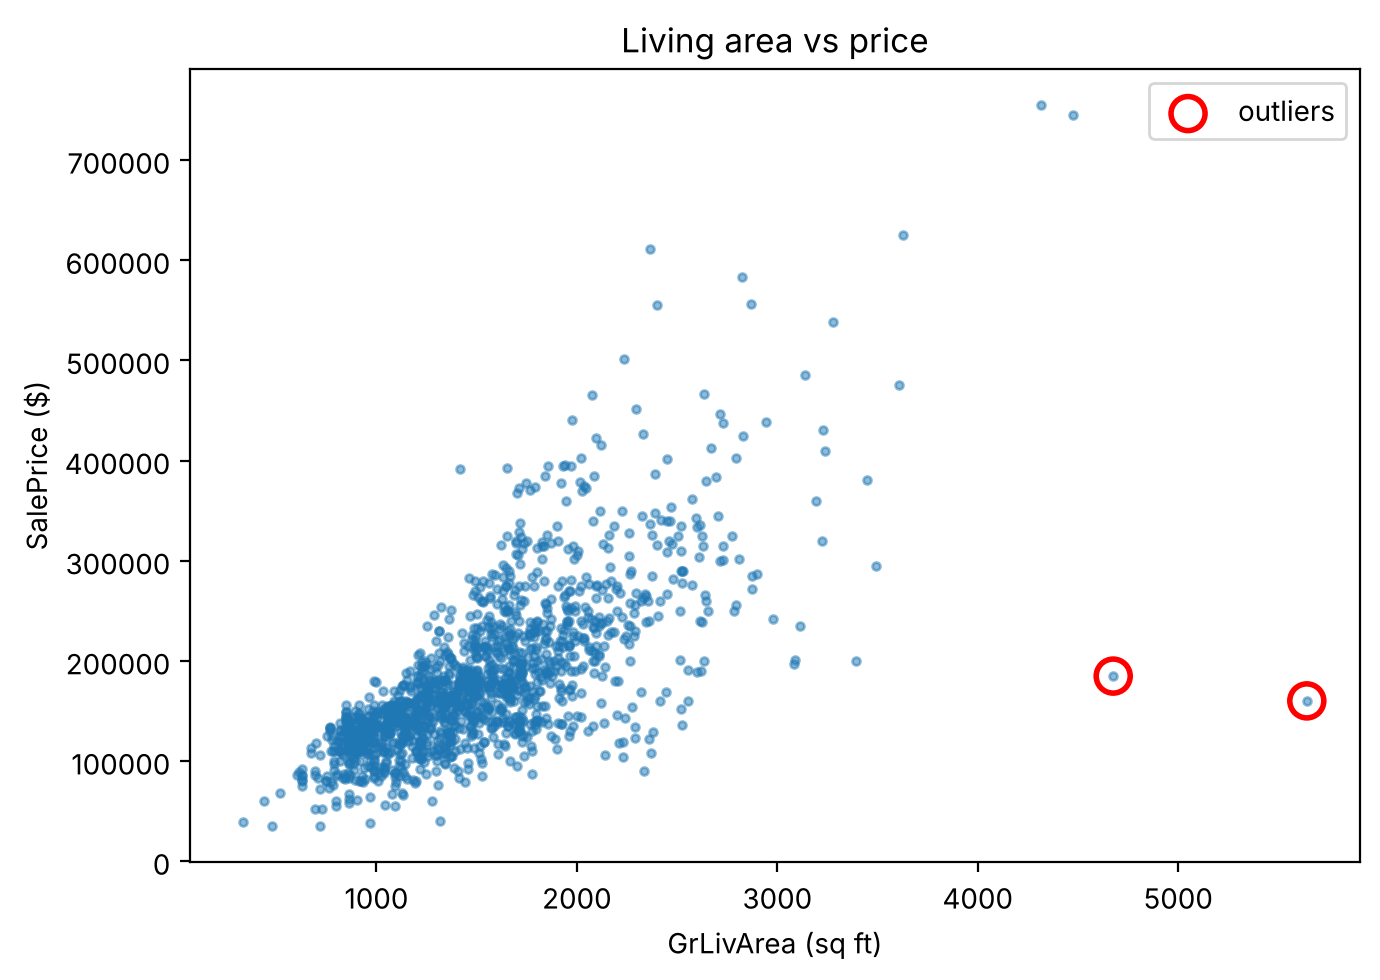

,Id,GrLivArea,SalePrice,OverallQual,SaleCondition
523,524,4676,184750,10,Partial
1298,1299,5642,160000,10,Partial


In [5]:
outlier = (train.GrLivArea > 4000) & (train.SalePrice < 300000)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(train.GrLivArea, train.SalePrice, s=8, alpha=0.5)
ax.scatter(train.GrLivArea[outlier], train.SalePrice[outlier], s=150,
           facecolors="none", edgecolors="red", linewidths=2, label="outliers")
ax.set(title="Living area vs price", xlabel="GrLivArea (sq ft)", ylabel="SalePrice ($)")
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "03_outliers.png", dpi=120)
plt.show()
train.loc[outlier, ["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition"]]

### 1.5 Which numeric columns move with price?
Correlation only sees straight-line relationships, and it ignores the 43 text columns.
It is a quick map, not a feature-selection rule.

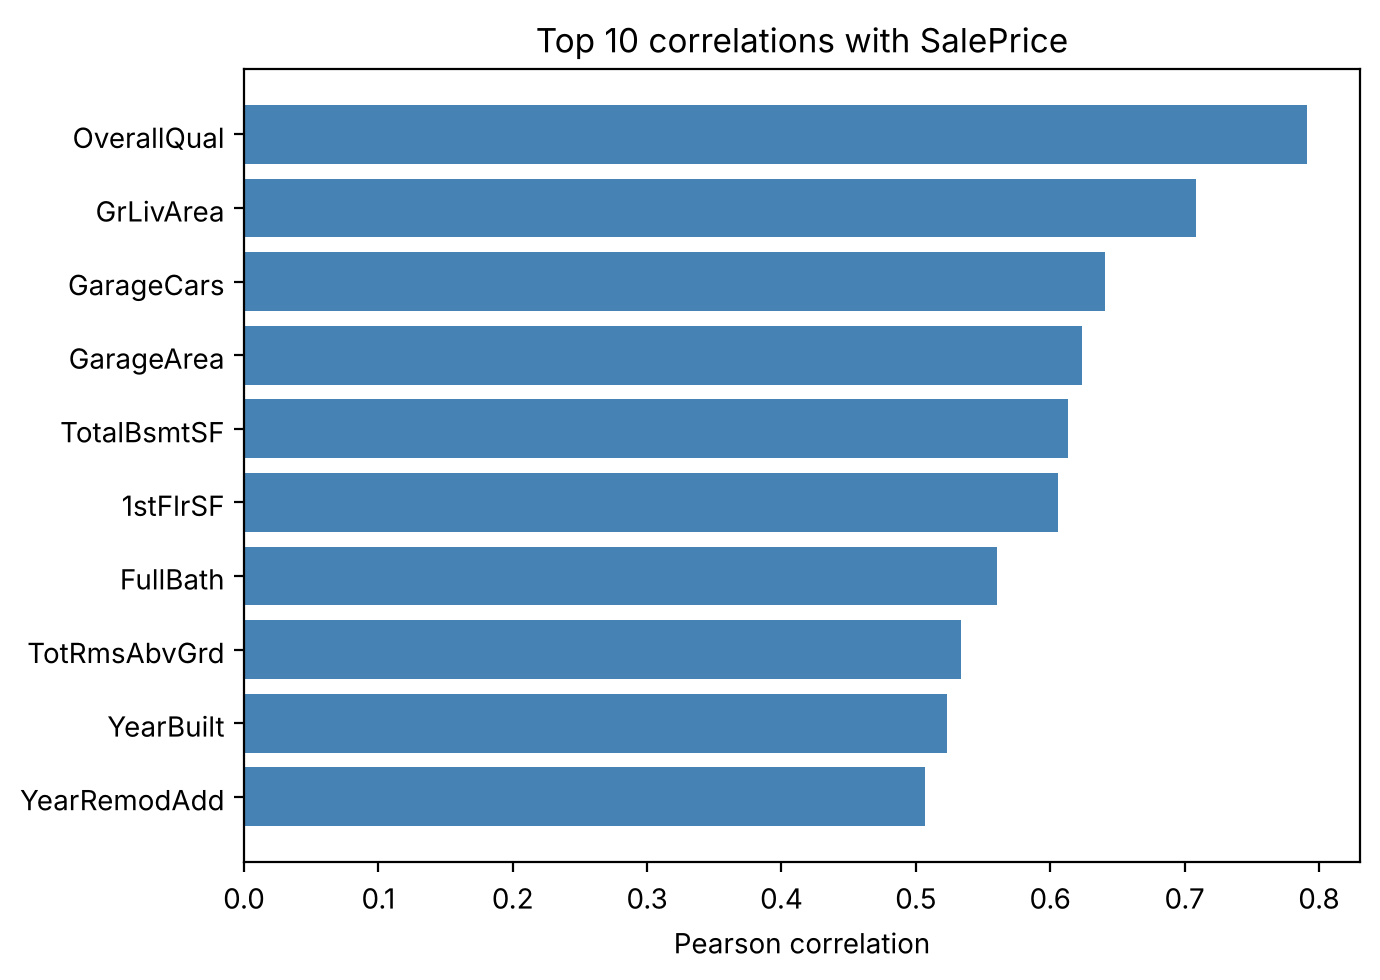

OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64

In [6]:
correlations = (train.select_dtypes("number").drop(columns="Id")
                .corr()["SalePrice"].drop("SalePrice").sort_values())
top10 = correlations.tail(10)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top10.index, top10.values, color="steelblue")
ax.set(title="Top 10 correlations with SalePrice", xlabel="Pearson correlation")
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "04_top_correlations.png", dpi=120)
plt.show()
top10.iloc[::-1].round(3)

### What EDA tells us to do next
| Finding | Action | Step |
|---|---|---|
| SalePrice is right-skewed; the metric is on log scale | Predict log(SalePrice) | Step 2 |
| Many NAs mean "doesn't have one" | Fill them with an explicit "absent" label | Step 3 |
| Quality and size dominate; size is spread across many columns | Build total-size and age features | Step 4 |
| Area columns are skewed like the price | Take log1p of skewed areas | Step 5 |
| Two huge-but-cheap houses | Test dropping them from training | Step 6 |

## Part 2: Baseline and cross-validation

### Why we need cross-validation (CV)
We can't score ourselves on `test`: its prices are hidden, and Kaggle limits daily
submissions. Scoring on the rows we trained on would be cheating, because the model has
already seen the answers. So we split `train` into **5 folds**. Each fold takes a turn as
"pretend test data", while a model is trained on the other 4. Every house is predicted exactly
once by a model that never saw it. These are the **out-of-fold (OOF)** predictions, and their
error is our **CV score**.

Every step in this notebook uses the **same 5 folds** (`random_state=42`), so differences
between steps come from our changes, not from luck in the split.

### Avoiding data leakage
Some preprocessing *learns from the data*. Filling gaps with the median, scaling, and
listing the categories for one-hot encoding all do. If we did those on all 1,460 rows before
splitting, every fold's "unseen" houses would already have influenced the training. That is
**data leakage**, and it makes CV look better than reality. Wrapping preprocessing and model
in one sklearn `Pipeline` means each fold re-learns the preprocessing from its own training
rows only.

In [7]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

kf = KFold(n_splits=5, shuffle=True, random_state=42)


def make_linear_preprocessor():
    """Numbers: fill gaps with the median, then scale. Text: fill gaps, then one-hot encode."""
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([
        ("num", numeric, make_column_selector(dtype_include="number")),
        ("cat", categorical, make_column_selector(dtype_exclude="number")),
    ])


def cv_evaluate(model, X, y, X_test, target="log", drop_outliers=False):
    """5-fold CV. Returns (cv_rmse, out-of-fold log predictions, averaged test log predictions)."""
    y = np.asarray(y, dtype=float)
    y_log = np.log(y)
    oof_log = np.zeros(len(X))
    test_log = np.zeros(len(X_test))
    for train_idx, valid_idx in kf.split(X):
        if drop_outliers:  # remove outliers from the training rows only; validation keeps them
            # `outlier` comes from Part 1.4 and uses the raw train data, so it still works
            # after later steps log-transform GrLivArea.
            train_idx = train_idx[~outlier.values[train_idx]]
        fold_model = clone(model)  # a fresh, untrained copy for every fold
        if target == "log":
            fold_model.fit(X.iloc[train_idx], y_log[train_idx])
            oof_log[valid_idx] = fold_model.predict(X.iloc[valid_idx])
            test_log += fold_model.predict(X_test) / kf.n_splits
        else:  # target == "raw": learn dollars, convert to log only for scoring
            fold_model.fit(X.iloc[train_idx], y[train_idx])
            floor = y[train_idx].min() / 2  # a raw-price model can predict <= 0; log needs > 0
            oof_log[valid_idx] = np.log(np.clip(fold_model.predict(X.iloc[valid_idx]), floor, None))
            test_log += np.log(np.clip(fold_model.predict(X_test), floor, None)) / kf.n_splits
    cv_rmse = np.sqrt(np.mean((y_log - oof_log) ** 2))
    return cv_rmse, oof_log, test_log


results = pd.DataFrame(columns=["step", "description", "cv_rmse"])


def record(step, description, cv_rmse):
    """Add one row to the results table (or replace it if the step was run before), print the
    change versus the previous row, and save the table."""
    global results
    step = str(step)
    row = pd.DataFrame([{"step": step, "description": description, "cv_rmse": cv_rmse}])
    if step in results.step.tolist():  # re-running a cell: replace its row, don't duplicate it
        results.loc[results.step == step, ["description", "cv_rmse"]] = [description, cv_rmse]
    else:
        results = row if results.empty else pd.concat([results, row], ignore_index=True)
    position = results.step.tolist().index(step)
    if position > 0:
        change = cv_rmse - results.cv_rmse.iloc[position - 1]
        print(f"Step {step}: CV RMSE {cv_rmse:.5f} ({change:+.5f} vs previous step)")
    else:
        print(f"Step {step}: CV RMSE {cv_rmse:.5f}")
    results.to_csv(OUT_DIR / "cv_results.csv", index=False)


def save_submission(name, test_log):
    """Turn log predictions back into dollars and write a Kaggle submission file."""
    submission = pd.DataFrame({"Id": test.Id, "SalePrice": np.exp(test_log)})
    assert len(submission) == 1459 and submission.Id.tolist() == sample.Id.tolist()
    assert np.isfinite(submission.SalePrice).all() and (submission.SalePrice > 0).all()
    (OUT_DIR / "submissions").mkdir(parents=True, exist_ok=True)
    submission.to_csv(OUT_DIR / "submissions" / f"{name}.csv", index=False)
    print("saved", name + ".csv")

### Step 0: predict the average price for every house
This is the "no model" reference point. Any real model must beat it.

In [8]:
X = train.drop(columns=["Id", "SalePrice"])
y = train.SalePrice
X_test = test.drop(columns="Id")

score, _, _ = cv_evaluate(DummyRegressor(strategy="mean"), X, y, X_test, target="raw")
record("0", "Predict the mean price", score)

Step 0: CV RMSE 0.40776


### Step 1: Ridge regression on the raw data
Ridge is linear regression with a penalty on large coefficients, $\alpha\sum_j \beta_j^2$.
With about 300 columns after one-hot encoding and only 1,460 houses, plain linear
regression would overfit. The penalty keeps the coefficients modest.

Here we train on **raw dollar prices** with only the minimum preprocessing. Every later step
changes one thing and is compared with this.

In [9]:
ridge_raw = Pipeline([("prep", make_linear_preprocessor()), ("model", Ridge(alpha=10))])
score, oof_step1, test_step1 = cv_evaluate(ridge_raw, X, y, X_test, target="raw")
record("1", "Ridge, raw price, minimal preprocessing", score)
save_submission("s1_ridge_raw", test_step1)

Step 1: CV RMSE 0.15534 (-0.25243 vs previous step)
saved s1_ridge_raw.csv


### Reading the numbers
A CV RMSE of 0.41 (Step 0) means a typical miss of about $e^{0.41}-1 \approx 50\%$.
Ridge cuts that to about 0.155, a typical miss of roughly 17%. But Step 1 still trains on
dollars while being scored in logs. Nothing stops a dollar model from predicting a price of
zero or less, so `cv_evaluate` puts a floor under raw predictions. It wasn't triggered here,
but it guards against a crash. Part 3 fixes this mismatch first.

In [10]:
results

,step,description,cv_rmse
0,0,Predict the mean price,0.407762
1,1,"Ridge, raw price, minimal preprocessing",0.155335


## Part 3: Feature engineering, one change at a time

Each step below changes **exactly one thing** and re-scores with the same 5 folds. That way,
the change in CV RMSE can be credited to that one change.

Row-wise feature code (sums, differences, relabelling) is plain pandas. It looks at one house
at a time and never at column statistics, so it can't leak information between folds. That
means it is safe to apply to `train` and `test` before CV. Anything that *learns* from a
column (medians, scaling, category lists) stays inside the Pipeline from Part 2.

One deliberate exception: in Step 5 we choose *which* columns to log-transform once, by
looking at their skewness in `train`. That choice uses the features only, never the price,
and it learns no numbers that go into the model, so its effect on CV is negligible.

### Step 2: predict log(SalePrice) instead of the price
Same Ridge, same features. The only change is `target="log"`: the model now learns
log(price), the scale Kaggle scores on and where the price is roughly symmetric (Part 1.2).

In [11]:
ridge = Pipeline([("prep", make_linear_preprocessor()), ("model", Ridge(alpha=10))])
score, _, _ = cv_evaluate(ridge, X, y, X_test, target="log")
record("2", "Predict log(SalePrice)", score)

Step 2: CV RMSE 0.15206 (-0.00327 vs previous step)


### Step 3: give missing values their real meaning
For many columns NA means "this house has none" (Part 1.3). We write that meaning down
explicitly, but **only when another column confirms it**. For example, a missing
`GarageType` becomes `"NoGarage"` only if `GarageArea` is 0. If the house *has* a garage
but its type is missing, it stays missing, and the Pipeline fills it as an unknown.

We also fix one column type. `MSSubClass` stores codes (20 = 1-storey 1946+, 60 = 2-storey
1946+, ...). They are labels, not quantities: code 60 isn't "three times" code 20. As a
number, Ridge would treat it as one; as text, it gets one-hot encoded like any category.

In [12]:
ABSENT_RULES = [  # (column that proves absence, columns to relabel, label)
    ("TotalBsmtSF", ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"], "NoBasement"),
    ("GarageArea", ["GarageType", "GarageFinish", "GarageQual", "GarageCond"], "NoGarage"),
    ("Fireplaces", ["FireplaceQu"], "NoFireplace"),
    ("PoolArea", ["PoolQC"], "NoPool"),
]


def fill_missing_meaning(df):
    df = df.copy()  # never change the caller's DataFrame
    for size_column, columns, label in ABSENT_RULES:
        absent = df[size_column] == 0
        for column in columns:
            df.loc[absent & df[column].isna(), column] = label
    # No size column exists for these; the data description says NA means "none".
    for column, label in [("Alley", "NoAlley"), ("Fence", "NoFence"), ("MiscFeature", "NoMisc")]:
        df[column] = df[column].fillna(label)
    df["MSSubClass"] = df["MSSubClass"].astype(str)
    return df


X3, X3_test = fill_missing_meaning(X), fill_missing_meaning(X_test)
score, _, _ = cv_evaluate(ridge, X3, y, X3_test, target="log")
record("3", "Missing values labelled by meaning; MSSubClass as category", score)

Step 3: CV RMSE 0.15106 (-0.00100 vs previous step)


### Step 4: new features that combine existing columns
A buyer thinks "how big is the house in total?", but the data splits size across several
columns. So we build the combined ideas directly.

**Expect little change for Ridge here.** A sum like `TotalSF` is a *linear* combination of
columns Ridge already has, so Ridge could already weight them that way. The totals start
to matter in Step 5: log(total) is *not* a sum of the parts' logs. They also matter for the
tree models in Part 4, which split on one column at a time.

| Feature | Formula | Idea |
|---|---|---|
| `TotalSF` | above-ground living area + basement area | overall size |
| `TotalBathrooms` | full baths + 0.5 × half baths (house + basement) | one comfort number |
| `HouseAge` | year sold − year built | age at the time of sale |
| `RemodelAge` | year sold − year remodelled | how fresh the interior is |
| `TotalPorchSF` | sum of the five deck/porch areas | outdoor space |

In [13]:
def add_new_features(df):
    df = df.copy()
    df["TotalSF"] = df["GrLivArea"] + df["TotalBsmtSF"]
    df["TotalBathrooms"] = (df["FullBath"] + 0.5 * df["HalfBath"]
                            + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"])
    df["HouseAge"] = (df["YrSold"] - df["YearBuilt"]).clip(lower=0)
    df["RemodelAge"] = (df["YrSold"] - df["YearRemodAdd"]).clip(lower=0)  # one row was remodelled after sale
    porches = ["WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]
    df["TotalPorchSF"] = df[porches].sum(axis=1)
    return df


X4, X4_test = add_new_features(X3), add_new_features(X3_test)
score, _, test_log = cv_evaluate(ridge, X4, y, X4_test, target="log")
record("4", "New features: TotalSF, TotalBathrooms, ages, TotalPorchSF", score)
save_submission("s2_new_features", test_log)

Step 4: CV RMSE 0.15121 (+0.00014 vs previous step)
saved s2_new_features.csv


### Step 5: log-transform skewed area columns
Area columns are right-skewed, just like the price was (skew table below). Price grows
roughly in *proportion* to size: an extra 100 sq ft matters more for a 600 sq ft house than
for a 4,000 sq ft one. A straight line can't express that on raw areas, but on log(area)
it can. `log1p(x) = log(1 + x)` is used because many areas are 0 (no porch), and log(0) is
undefined.

**Which columns?** Every area column with skewness above 0.75 in `train`. The skew table
is printed below. We fixed the list once and wrote it into the code. It uses only the
features, never the price, so it carries no target information.

In [14]:
AREA_COLUMNS = ["LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
                "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "GrLivArea", "GarageArea",
                "WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch",
                "PoolArea", "MiscVal", "TotalSF", "TotalPorchSF"]
skewness = X4[AREA_COLUMNS].skew().sort_values(ascending=False)
print(skewness.round(2).to_string())

SKEWED_COLUMNS = ["MiscVal", "PoolArea", "LotArea", "3SsnPorch", "LowQualFinSF", "BsmtFinSF2",
                  "ScreenPorch", "EnclosedPorch", "MasVnrArea", "OpenPorchSF", "LotFrontage",
                  "TotalSF", "BsmtFinSF1", "WoodDeckSF", "TotalBsmtSF", "1stFlrSF", "GrLivArea",
                  "TotalPorchSF", "BsmtUnfSF", "2ndFlrSF"]  # all skew > 0.75 (GarageArea is 0.18)
assert set(SKEWED_COLUMNS) == set(skewness[skewness > 0.75].index)


def log_skewed(df):
    df = df.copy()
    df[SKEWED_COLUMNS] = np.log1p(df[SKEWED_COLUMNS])
    return df

MiscVal          24.48
PoolArea         14.83
LotArea          12.21
3SsnPorch        10.30
LowQualFinSF      9.01
BsmtFinSF2        4.26
ScreenPorch       4.12
EnclosedPorch     3.09
MasVnrArea        2.67
OpenPorchSF       2.36
LotFrontage       2.16
TotalSF           1.78
BsmtFinSF1        1.69
WoodDeckSF        1.54
TotalBsmtSF       1.52
1stFlrSF          1.38
GrLivArea         1.37
TotalPorchSF      1.10
BsmtUnfSF         0.92
2ndFlrSF          0.81
GarageArea        0.18


In [15]:
X5, X5_test = log_skewed(X4), log_skewed(X4_test)
score, _, test_log = cv_evaluate(ridge, X5, y, X5_test, target="log")
record("5", "log1p of skewed area columns", score)
save_submission("s3_log_features", test_log)

Step 5: CV RMSE 0.13239 (-0.01882 vs previous step)
saved s3_log_features.csv


### Step 6: drop the two huge-but-cheap houses from training
They are removed **from each fold's training rows only** (Part 1.4). They are still predicted
and still count in the CV score. Removing them from scoring as well would flatter us,
because the hidden test set may contain houses like them.

In [16]:
score, _, test_log = cv_evaluate(ridge, X5, y, X5_test, target="log", drop_outliers=True)
record("6", "Drop 2 outliers from training folds", score)

Step 6: CV RMSE 0.12766 (-0.00473 vs previous step)


### Tuning Ridge's alpha
`alpha=10` was a guess. We try a few values with the same CV and keep the best. Each value
is a separate experiment on the same folds, so this is a fair comparison. If the best value
lands on the edge of the grid, the true best might lie beyond it, so the grid should widen.

In [17]:
alpha_scores = {}
for alpha in [1, 3, 10, 30, 100]:
    candidate = Pipeline([("prep", make_linear_preprocessor()), ("model", Ridge(alpha=alpha))])
    alpha_scores[alpha], _, _ = cv_evaluate(candidate, X5, y, X5_test, target="log", drop_outliers=True)
    print(f"alpha={alpha:>3}: CV RMSE {alpha_scores[alpha]:.5f}")
best_alpha = min(alpha_scores, key=alpha_scores.get)
print("best alpha:", best_alpha)

ridge = Pipeline([("prep", make_linear_preprocessor()), ("model", Ridge(alpha=best_alpha))])
score, oof_ridge, test_log = cv_evaluate(ridge, X5, y, X5_test, target="log", drop_outliers=True)
record("6b", f"Ridge alpha tuned to {best_alpha}", score)
save_submission("s4_no_outliers", test_log)

# These are the features that Parts 4 and 5 build on.
X_final, X_test_final = X5, X5_test

alpha=  1: CV RMSE 0.13027


alpha=  3: CV RMSE 0.12843


alpha= 10: CV RMSE 0.12766


alpha= 30: CV RMSE 0.12797


alpha=100: CV RMSE 0.12980
best alpha: 10


Step 6b: CV RMSE 0.12766 (+0.00000 vs previous step)
saved s4_no_outliers.csv


### Which feature engineering helped most?

In [18]:
part3 = results[results.step.isin(["1", "2", "3", "4", "5", "6", "6b"])].copy()
part3["improvement"] = -part3.cv_rmse.diff()
part3

,step,description,cv_rmse,improvement
1,1,"Ridge, raw price, minimal preprocessing",0.155335,NaN
2,2,Predict log(SalePrice),0.152063,0.003272
3,3,Missing values labelled by meaning; MSSubClass...,0.151065,0.000998
4,4,"New features: TotalSF, TotalBathrooms, ages, T...",0.151209,-0.000145
5,5,log1p of skewed area columns,0.132386,0.018823
6,6,Drop 2 outliers from training folds,0.127656,0.004730
7,6b,Ridge alpha tuned to 10,0.127656,-0.000000


## Part 4: Comparing models

The features are now fixed (`X_final` from Part 3, plus a tree-friendly version for
CatBoost). Every model below uses the **same folds, the log target, and the outlier rule**.
So the only thing that changes is the model. Each model's out-of-fold (OOF) and test
predictions are kept in two dictionaries, `oof` and `test_preds`, for blending in Part 5.

| Family | Models | Idea |
|---|---|---|
| Linear | Ridge, Lasso, ElasticNet | price = weighted sum of features, with a penalty |
| Tree ensembles | Random Forest, XGBoost, CatBoost | many decision trees, combined |
| Kernel | SVR | a smooth curve fitted in a transformed space |

In [19]:
import time

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso
from sklearn.svm import SVR
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

oof, test_preds, seconds = {}, {}, {}


def run_model(step, name, description, model, X_train, X_predict):
    """Score one model with the shared CV, keep its predictions, and record it
    (step=None: keep the predictions but don't add a row to the results table)."""
    started = time.time()
    score, oof[name], test_preds[name] = cv_evaluate(model, X_train, y, X_predict,
                                                      target="log", drop_outliers=True)
    seconds[name] = time.time() - started
    if step is None:
        print(f"{name}: CV RMSE {score:.5f}", end="")
    else:
        record(step, description, score)
    print(f"   ({seconds[name]:.0f} s)")


def linear_pipeline(model):
    return Pipeline([("prep", make_linear_preprocessor()), ("model", model)])


# Ridge was already scored as step 6b; re-run it only to keep its predictions for Part 5.
run_model(None, "ridge", "Ridge", linear_pipeline(Ridge(alpha=best_alpha)), X_final, X_test_final)

ridge: CV RMSE 0.12766   (0 s)


### Step 7: Lasso and ElasticNet, two other penalties
- **Ridge** penalises `alpha × Σ coefficient²`. It shrinks every coefficient but never to
  exactly zero.
- **Lasso** penalises `alpha × Σ |coefficient|`. That pushes weak features to **exactly
  zero**, so Lasso also does feature selection.
- **ElasticNet** mixes the two (`l1_ratio` = share of the Lasso penalty).

Their alphas live on a much smaller scale than Ridge's, because the penalty is written
differently in sklearn. We try a small grid for each and keep the best.

In [20]:
def tune_alpha(make_model, alphas, label):
    """Score make_model(alpha) for each alpha with the shared CV; return the best alpha."""
    scores = {}
    for alpha in alphas:
        scores[alpha], _, _ = cv_evaluate(linear_pipeline(make_model(alpha)),
                                          X_final, y, X_test_final, drop_outliers=True)
        print(f"{label} alpha={alpha}: {scores[alpha]:.5f}")
    return min(scores, key=scores.get)


lasso_alpha = tune_alpha(lambda a: Lasso(alpha=a, max_iter=50000), [0.0002, 0.0005, 0.001], "Lasso")
enet_alpha = tune_alpha(lambda a: ElasticNet(alpha=a, l1_ratio=0.5, max_iter=50000),
                        [0.0005, 0.001, 0.002], "ElasticNet")

Lasso alpha=0.0002: 0.12611


Lasso alpha=0.0005: 0.12546


Lasso alpha=0.001: 0.12748


ElasticNet alpha=0.0005: 0.12565


ElasticNet alpha=0.001: 0.12569


ElasticNet alpha=0.002: 0.12766


In [21]:
run_model("7", "lasso", f"Lasso (alpha={lasso_alpha})",
          linear_pipeline(Lasso(alpha=lasso_alpha, max_iter=50000)), X_final, X_test_final)
run_model("7b", "elasticnet", f"ElasticNet (alpha={enet_alpha}, l1_ratio=0.5)",
          linear_pipeline(ElasticNet(alpha=enet_alpha, l1_ratio=0.5, max_iter=50000)),
          X_final, X_test_final)

Step 7: CV RMSE 0.12546 (-0.00219 vs previous step)
   (2 s)


Step 7b: CV RMSE 0.12565 (+0.00018 vs previous step)
   (3 s)


In [22]:
lasso_fit = linear_pipeline(Lasso(alpha=lasso_alpha, max_iter=50000)).fit(X_final[~outlier], np.log(y[~outlier]))
coefficients = lasso_fit.named_steps["model"].coef_
print(f"Lasso kept {np.sum(coefficients != 0)} of {len(coefficients)} columns (the rest are exactly 0)")

Lasso kept 107 of 324 columns (the rest are exactly 0)


### Step 8: Random Forest (bagging)
A **decision tree** asks yes/no questions ("OverallQual ≥ 8?", "TotalSF > 2,500?") and
predicts the average price of the houses that end up in each leaf. A single deep tree
memorises the training data (overfits). A **Random Forest** grows hundreds of trees, each on
a random bootstrap sample of the houses and a random subset of the columns, and averages
them. Averaging many different noisy trees cancels much of the noise. This is **bagging**.

Trees only split on thresholds, so scaling and log transforms don't matter to them. They
also find interactions (e.g. "large **and** high quality") without being told.

In [23]:
run_model("8", "rf", "Random Forest (300 trees)",
          linear_pipeline(RandomForestRegressor(n_estimators=300, max_features=0.3,
                                                min_samples_leaf=2, n_jobs=-1, random_state=42)),
          X_final, X_test_final)

Step 8: CV RMSE 0.13822 (+0.01258 vs previous step)
   (12 s)


### Step 9: XGBoost (boosting)
**Boosting** builds trees **one after another**. Each new small tree is fitted to the errors
the previous trees still make, and only a small fraction of it is added (the learning
rate). Bagging averages independent trees to cut noise; boosting adds dependent trees to
cut bias. Settings: 1,500 shallow trees (depth 3), learning rate 0.03, and each tree sees
80% of houses and 50% of columns (more randomness, less overfitting).

In [24]:
run_model("9", "xgb", "XGBoost (1500 trees, depth 3, lr 0.03)",
          linear_pipeline(XGBRegressor(n_estimators=1500, learning_rate=0.03, max_depth=3,
                                       subsample=0.8, colsample_bytree=0.5, min_child_weight=2,
                                       n_jobs=-1, random_state=42)),
          X_final, X_test_final)

Step 9: CV RMSE 0.12310 (-0.01513 vs previous step)
   (4 s)


### Step 10: CatBoost (boosting with native categories)
CatBoost is also gradient boosting, but it handles **text columns directly**. It replaces
each category by a smoothed average of the target, computed in a careful order to avoid
leakage, instead of exploding it into hundreds of one-hot columns. It also builds
*symmetric* trees, which tend to overfit less on small data.

Input: the Step 4 features (meaningful NA labels + new features). Logs aren't needed for
trees. Remaining text gaps are filled with `"Missing"`, because CatBoost requires text in
category columns.

In [25]:
categorical_columns = X4.select_dtypes(exclude="number").columns.tolist()
X_cat = X4.copy()
X_cat_test = X4_test.copy()
X_cat[categorical_columns] = X_cat[categorical_columns].fillna("Missing")
X_cat_test[categorical_columns] = X_cat_test[categorical_columns].fillna("Missing")

catboost = CatBoostRegressor(iterations=1500, learning_rate=0.03, depth=6, l2_leaf_reg=3,
                             # a tuple, not a list: sklearn's clone() (used in cv_evaluate)
                             # cannot copy CatBoost when cat_features is a list
                             cat_features=tuple(categorical_columns), random_seed=42,
                             verbose=0, allow_writing_files=False)
run_model("10", "catboost", "CatBoost (1500 trees, depth 6, native categories)",
          catboost, X_cat, X_cat_test)
save_submission("s5_catboost", test_preds["catboost"])

Step 10: CV RMSE 0.12320 (+0.00010 vs previous step)
   (86 s)
saved s5_catboost.csv


### Step 11: Support Vector Regression (SVR)
SVR with an RBF kernel predicts a house's price from its **similarity** to the training
houses. Similarity is based on distance in feature space, which is why scaling (done in our
Pipeline) is essential. Errors smaller than `epsilon` are ignored. `C` sets how hard the
model tries to fit the rest, and `gamma` sets how local "similar" is.

The grid was widened twice, because the best pair kept landing on its edge. In the reference
run the best pair (C=1, gamma=0.003) still sits on a corner, so the next cell also checks a few
pairs just beyond that corner. If they all score worse, the corner is the best point in its
neighbourhood. That is a local minimum, not a proof that nothing better exists anywhere.

In [26]:
svr_scores = {}
for C in [1, 3, 10, 30]:
    for gamma in [0.0001, 0.0003, 0.001, 0.003]:
        svr_scores[(C, gamma)], _, _ = cv_evaluate(
            linear_pipeline(SVR(C=C, epsilon=0.01, gamma=gamma)),
            X_final, y, X_test_final, drop_outliers=True)
        print(f"SVR C={C}, gamma={gamma}: {svr_scores[(C, gamma)]:.5f}")
best_C, best_gamma = min(svr_scores, key=svr_scores.get)

SVR C=1, gamma=0.0001: 0.14474


SVR C=1, gamma=0.0003: 0.13183


SVR C=1, gamma=0.001: 0.12572


SVR C=1, gamma=0.003: 0.12349


SVR C=3, gamma=0.0001: 0.13234


SVR C=3, gamma=0.0003: 0.12729


... (6 outputs left out)

SVR C=30, gamma=0.0001: 0.12684


SVR C=30, gamma=0.0003: 0.12828


SVR C=30, gamma=0.001: 0.13193


SVR C=30, gamma=0.003: 0.13985


In [27]:
# Check a few pairs just outside the grid's corner (not used for choosing, only for checking).
for C, gamma in [(0.3, 0.003), (1, 0.005), (1, 0.01), (0.3, 0.01)]:
    score, _, _ = cv_evaluate(linear_pipeline(SVR(C=C, epsilon=0.01, gamma=gamma)),
                              X_final, y, X_test_final, drop_outliers=True)
    print(f"beyond the grid: SVR C={C}, gamma={gamma}: {score:.5f}")
print(f"best on the grid: C={best_C}, gamma={best_gamma}: {svr_scores[(best_C, best_gamma)]:.5f}")

run_model("11", "svr", f"SVR (C={best_C}, gamma={best_gamma})",
          linear_pipeline(SVR(C=best_C, epsilon=0.01, gamma=best_gamma)), X_final, X_test_final)

beyond the grid: SVR C=0.3, gamma=0.003: 0.12558


beyond the grid: SVR C=1, gamma=0.005: 0.12431


beyond the grid: SVR C=1, gamma=0.01: 0.12999


beyond the grid: SVR C=0.3, gamma=0.01: 0.13022
best on the grid: C=1, gamma=0.003: 0.12349


Step 11: CV RMSE 0.12349 (+0.00029 vs previous step)
   (5 s)


### Model comparison

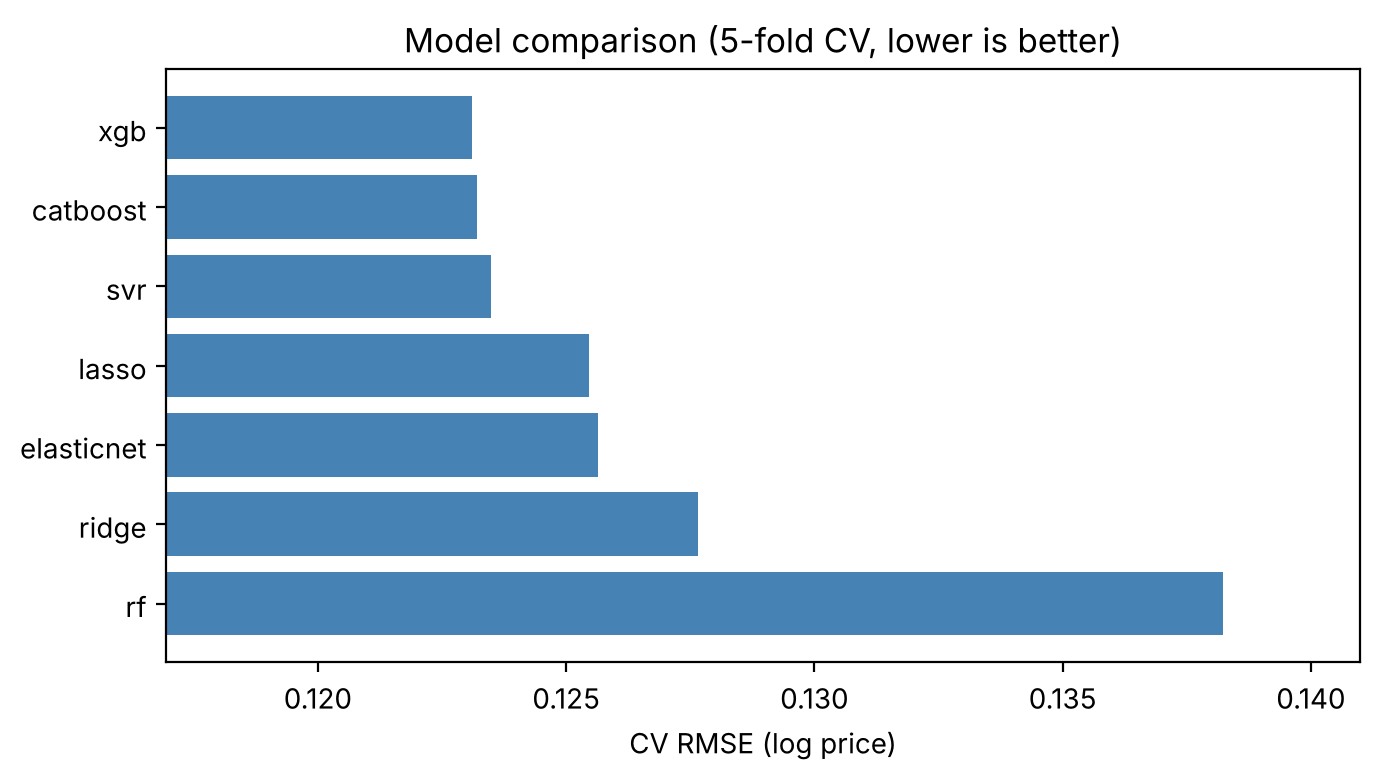

,cv_rmse,seconds
xgb,0.12310,4.28225
catboost,0.12320,85.89718
svr,0.12349,4.75585
lasso,0.12546,1.97144
elasticnet,0.12565,2.81175
ridge,0.12766,0.42453
rf,0.13822,12.38169


In [28]:
names = ["ridge", "lasso", "elasticnet", "rf", "xgb", "catboost", "svr"]
y_log = np.log(y.values)
comparison = pd.DataFrame({
    "cv_rmse": [np.sqrt(np.mean((y_log - oof[name]) ** 2)) for name in names],
    "seconds": [seconds[name] for name in names],
}, index=names).sort_values("cv_rmse")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(comparison.index[::-1], comparison.cv_rmse[::-1], color="steelblue")
ax.set(title="Model comparison (5-fold CV, lower is better)", xlabel="CV RMSE (log price)",
       xlim=(comparison.cv_rmse.min() * 0.95, comparison.cv_rmse.max() * 1.02))
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "05_model_comparison.png", dpi=120)
plt.show()
comparison.round(5)

## Part 5: Blending, and the whole pathway at a glance

### Why averaging models can beat the best model
Each model makes errors. If two models make **different** errors (one guesses too high where
the other guesses too low), averaging them cancels part of both. If they make the **same**
errors, averaging changes nothing. So the useful question is not just "how good is each
model?" but "**how differently do they go wrong?**"

We measure that with the correlation between their out-of-fold **residuals** (true log price
minus predicted log price). 1.0 means identical mistakes. Lower means more to gain from
combining.

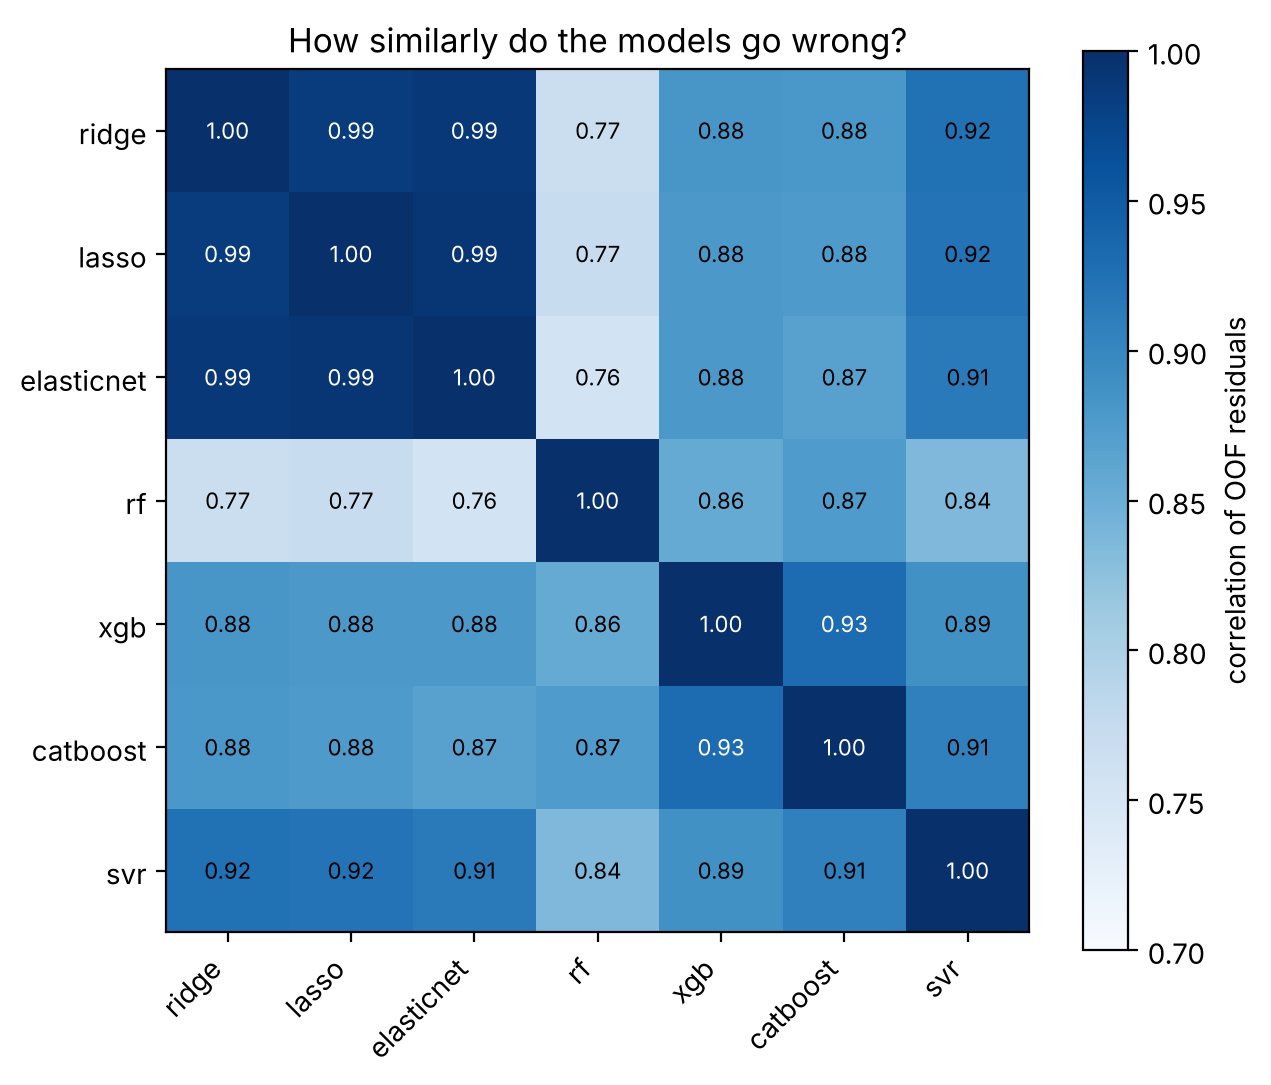

In [29]:
residuals = pd.DataFrame({name: y_log - oof[name] for name in names})
residual_corr = residuals.corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(residual_corr, cmap="Blues", vmin=0.7, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        value = residual_corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if value > 0.93 else "black")  # readable on dark cells
fig.colorbar(image, label="correlation of OOF residuals")
ax.set_title("How similarly do the models go wrong?")
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "06_oof_correlation.png", dpi=120)
plt.show()

**Reading the heatmap.**
- Ridge, Lasso and ElasticNet correlate at 0.99–1.00: they make almost the same mistakes, so
  blending them with each other gains little.
- Linear models vs boosted trees: about 0.88, the most different pair among the good models.
- XGBoost vs CatBoost: 0.93. They are both boosting, but they treat categories differently
  (one-hot vs target statistics).
- SVR sits in between (0.89–0.92).

### Choosing the blend
**Rule, fixed before looking at blend scores:** take the best model from each family, plus
both boosters because they handle categories differently. That gives **Lasso + XGBoost +
CatBoost + SVR**, with **equal weights**. We skip Random Forest (much weaker), and we skip
Ridge and ElasticNet (near-copies of Lasso).

**Why equal weights instead of tuning them?** Weights tuned on the same 1,460 OOF
predictions would fit those predictions' noise. That is overfitting again, one level up.
Equal weights are a choice we can defend without looking at the score.

In [30]:
blend_names = ["lasso", "xgb", "catboost", "svr"]
blend_oof = np.mean([oof[name] for name in blend_names], axis=0)
blend_test = np.mean([test_preds[name] for name in blend_names], axis=0)
blend_score = np.sqrt(np.mean((y_log - blend_oof) ** 2))
record("12", "Blend: Lasso + XGBoost + CatBoost + SVR, equal weights", blend_score)
save_submission("s6_blend", blend_test)

Step 12: CV RMSE 0.11906 (-0.00442 vs previous step)
saved s6_blend.csv


For context only (these did **not** choose the blend), here is what simpler or larger
blends score. Throwing in every model is worse, because three near-identical linear models
then take three of the six votes.

In [31]:
def blend_rmse(chosen):
    return np.sqrt(np.mean((y_log - np.mean([oof[n] for n in chosen], axis=0)) ** 2))

pd.Series({
    f"best single model ({comparison.index[0]})": comparison.cv_rmse.min(),
    "XGBoost + CatBoost": blend_rmse(["xgb", "catboost"]),
    "Lasso + XGBoost": blend_rmse(["lasso", "xgb"]),
    "chosen 4-model blend": blend_score,
    "all models except Random Forest": blend_rmse([n for n in names if n != "rf"]),
}).round(5).to_frame("cv_rmse")

,cv_rmse
best single model (xgb),0.12310
XGBoost + CatBoost,0.12099
Lasso + XGBoost,0.12044
chosen 4-model blend,0.11906
all models except Random Forest,0.12022


### The whole pathway: improvement staircase

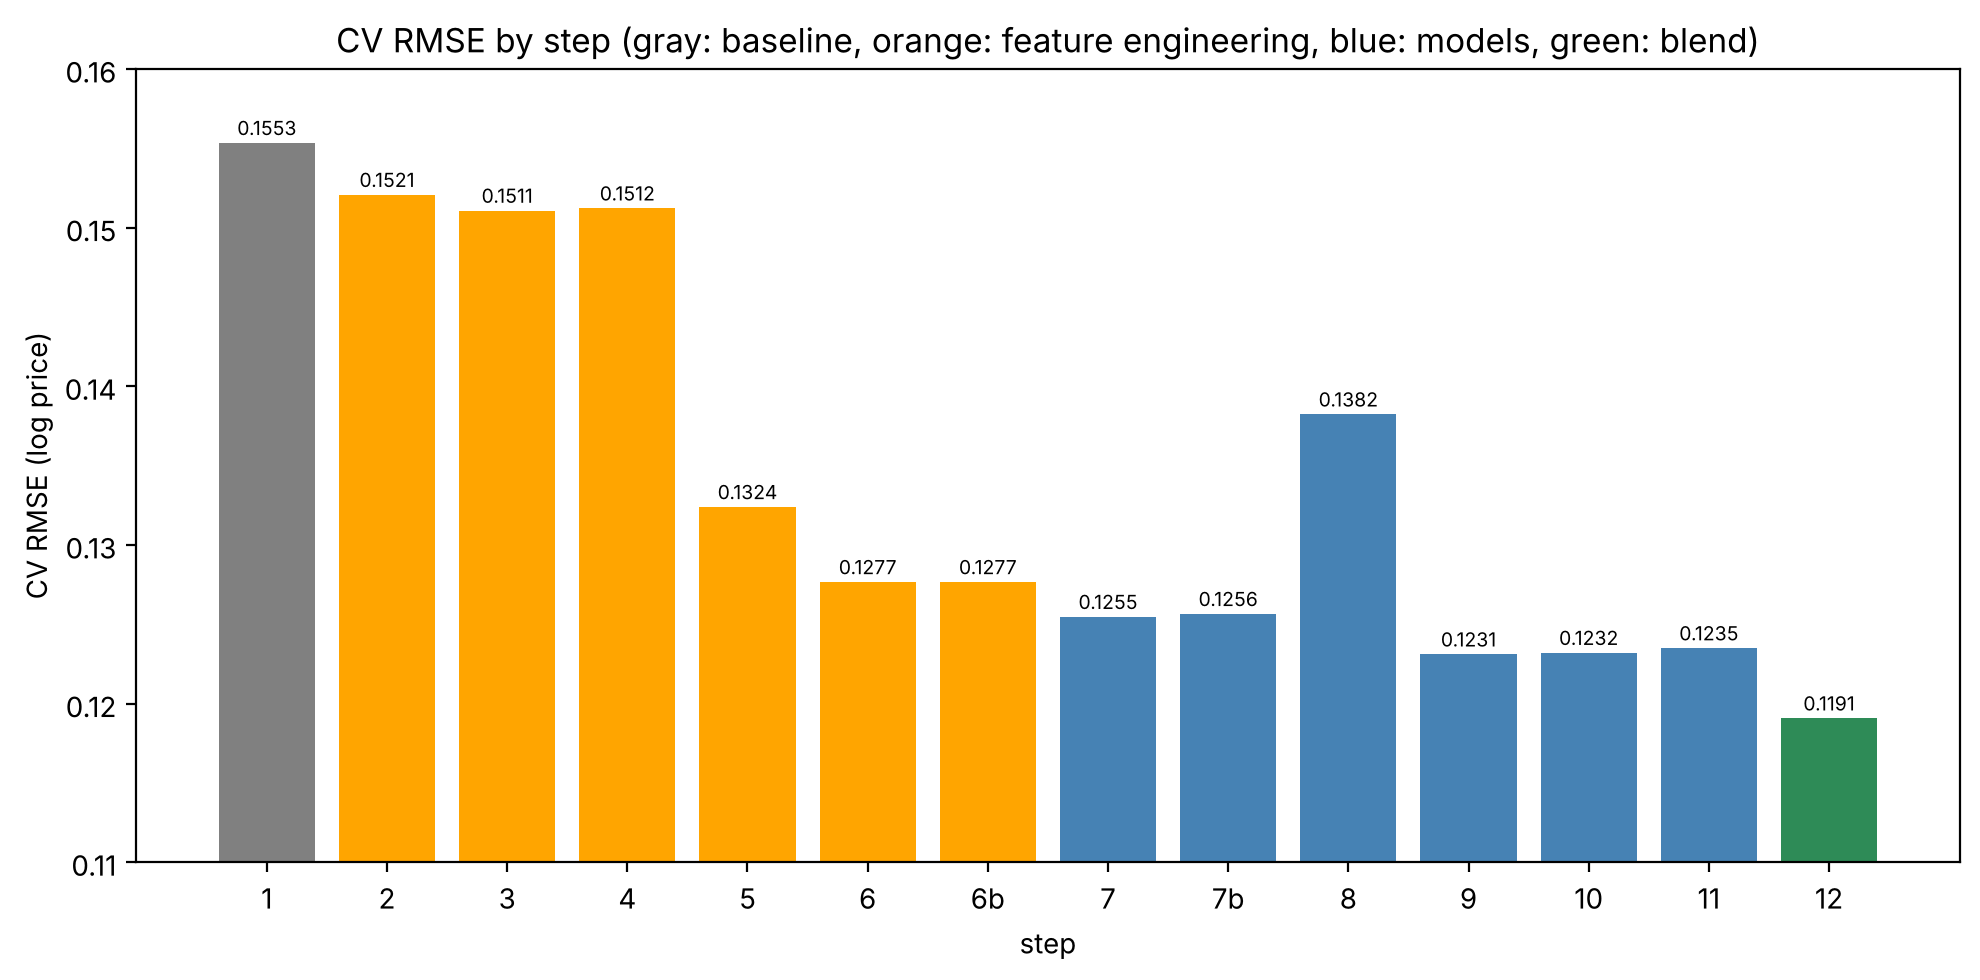

Step 0 (predict the mean) scored 0.4078; it is left off the chart.


In [32]:
steps = results[results.step != "0"].reset_index(drop=True)  # step 0 (0.41) would flatten the chart
colors = ["gray" if s == "1" else "orange" if s in {"2", "3", "4", "5", "6", "6b"}
          else "steelblue" if s != "12" else "seagreen" for s in steps.step]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(steps.step, steps.cv_rmse, color=colors)
for i, value in enumerate(steps.cv_rmse):
    ax.text(i, value + 0.0005, f"{value:.4f}", ha="center", fontsize=7)
ax.set(title="CV RMSE by step (gray: baseline, orange: feature engineering, "
             "blue: models, green: blend)",
       xlabel="step", ylabel="CV RMSE (log price)", ylim=(0.11, 0.16))
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "07_improvement_staircase.png", dpi=120)
plt.show()
print(f"Step 0 (predict the mean) scored {results.cv_rmse.iloc[0]:.4f}; it is left off the chart.")

### Submissions made in this notebook
Upload them in this order and record each Kaggle score. The jump from **S2 to S3** changes one
thing (log of skewed areas), which makes it the cleanest "best improvement" case to explain.

In [33]:
submission_steps = {"s1_ridge_raw": "1", "s2_new_features": "4", "s3_log_features": "5",
                    "s4_no_outliers": "6b", "s5_catboost": "10", "s6_blend": "12"}
cv_by_step = results.set_index("step").cv_rmse
summary = pd.DataFrame({
    "submission": list(submission_steps),
    "step": list(submission_steps.values()),
    "cv_rmse": [cv_by_step[s] for s in submission_steps.values()],
})
summary.to_csv(OUT_DIR / "submission_summary.csv", index=False)
summary.round(5)

,submission,step,cv_rmse
0,s1_ridge_raw,1,0.15534
1,s2_new_features,4,0.15121
2,s3_log_features,5,0.13239
3,s4_no_outliers,6b,0.12766
4,s5_catboost,10,0.12320
5,s6_blend,12,0.11906


## Summary
- **Most useful feature engineering:** log1p of skewed area columns (Step 5), −12.4% CV RMSE
  on its own. Price scales with size in proportion, so log price is close to linear in log
  area. Together with the log target, that matches what a linear model can express.
- **Best single models:** gradient boosting (XGBoost, CatBoost). Bagging (Random Forest) was
  the weakest, because averaging can't remove the bias that every tree shares.
- **Final model:** an equal-weight blend of four models from different families. It beats
  the best single model, because their errors are only partly correlated.
- **Limits:** every choice was made with the same 5-fold CV, so the CV scores are slightly
  optimistic. The Kaggle leaderboard is the independent check.